In [2]:
from pathlib import Path # handles file paths on any computer
import spikeinterface.extractors as se # SpikeInterface readers for many recording formats

data_dir = Path("../data/raw") # raw-data folder, relative to notebooks/
file_path = data_dir / "maxone_record_000011.raw.h5" # the test file
print("File exists:", file_path.exists()) # should print True

rec = se.read_maxwell(file_path) # open the recording (reads metadata only, not all the data)
print(rec) # one-line summary

fs = rec.get_sampling_frequency() # samples per second (Hz)
n_ch = rec.get_num_channels() # number of recorded electrodes
dur = rec.get_total_duration() # length in seconds
print(f"Sampling rate: {fs:.0f} Hz") # usually 20000 Hz for MaxWell
print(f"Channels: {n_ch}") # up to 1024 recorded at once
print(f"Duration: {dur:.2f} s") # short for a test file
print("Data type:", rec.get_dtype()) # how each sample is stored

File exists: True
The h5 compression library for Maxwell is already located in /Users/arelibalderas/hdf5_plugin_path_maxwell/libcompression.dylib!
MaxwellRecordingExtractor: 25 channels - 20.0kHz - 1 segments - 1,201,200 samples 
                           60.06s (1.00 minutes) - uint16 dtype - 57.28 MiB
  file_path: /Users/arelibalderas/git_repos/hdmea-organoid-pipeline/notebooks/../data/raw/maxone_record_000011.raw.h5
Sampling rate: 20000 Hz
Channels: 25
Duration: 60.06 s
Data type: uint16


Gain: 6.294 µV per ADC count
First 5 electrode positions (x, y) in µm:
 [[1907.5  700. ]
 [1855.   682.5]
 [1872.5  682.5]
 [1837.5  682.5]
 [1890.   700. ]]
Traces shape (samples, channels): (1200000, 25)
Channel 881: min -169.9 µV, max 88.1 µV


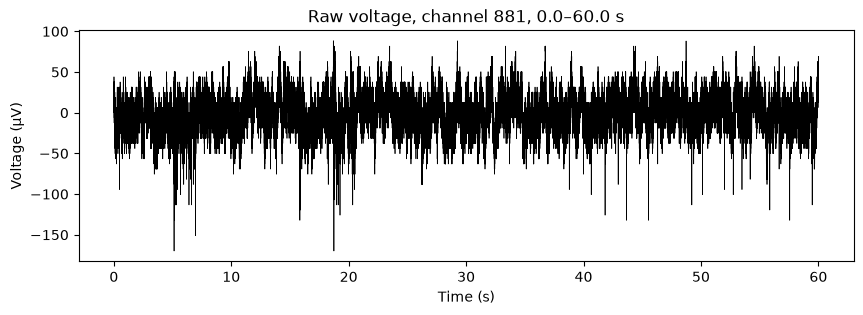

In [18]:
import numpy as np # arrays and maths
import matplotlib.pyplot as plt # plotting

gain = rec.get_channel_gains()[0] # µV per ADC count (same for all channels)
print(f"Gain: {gain:.3f} µV per ADC count") # converts raw counts to voltage

locs = rec.get_channel_locations() # (x, y) position of each electrode on the chip, in µm
print("First 5 electrode positions (x, y) in µm:\n", locs[:5]) # where on the array we recorded

ch = 1 # which channel to look at (0 = first); change freely
t_start = 0.0 # start time in s
t_len = 60.0 # window length in s
s0 = int(t_start * fs) # first sample index
s1 = int((t_start + t_len) * fs) # last sample index
traces = rec.get_traces(start_frame=s0, end_frame=s1, return_in_uV=True) # read only this window, already in µV
print("Traces shape (samples, channels):", traces.shape) # expect (20000, 25) for 1 s

v = traces[:, ch] - np.median(traces[:, ch]) # remove the baseline so the trace sits around 0 µV
time = np.arange(s0, s1) / fs # time axis in s
print(f"Channel {rec.get_channel_ids()[ch]}: min {v.min():.1f} µV, max {v.max():.1f} µV") # voltage range in this window

plt.figure(figsize=(10, 3)) # wide, short figure for a time trace
plt.plot(time, v, lw=0.5, color="black") # raw voltage trace
plt.xlabel("Time (s)") # x axis label with units
plt.ylabel("Voltage (µV)") # y axis label with units
plt.title(f"Raw voltage, channel {rec.get_channel_ids()[ch]}, {t_start:.1f}–{t_start + t_len:.1f} s") # title updates with your settings
plt.show() # draw it

BandpassFilterRecording: 25 channels - 20.0kHz - 1 segments - 1,201,200 samples 
                         60.06s (1.00 minutes) - float32 dtype - 114.56 MiB
Raw:      min -169.9 µV, max 88.1 µV
Filtered: min -160.5 µV, max 73.9 µV


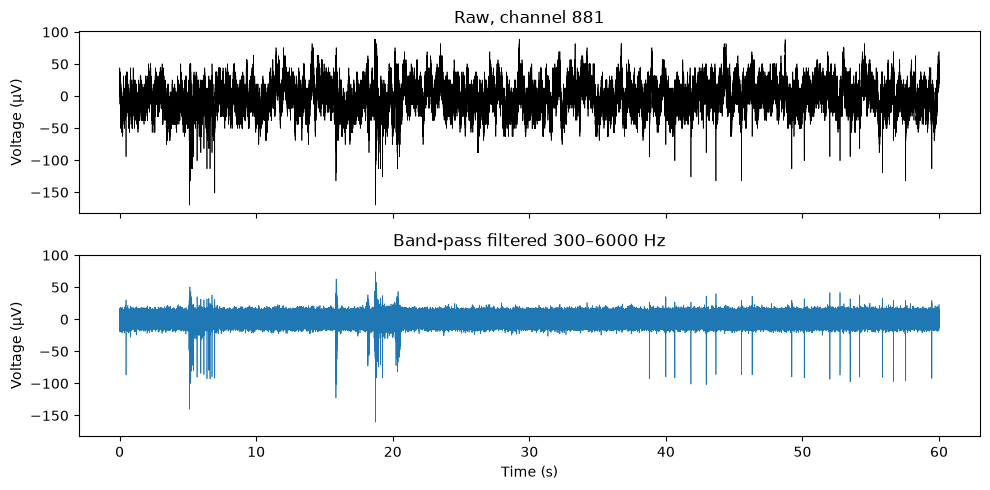

In [19]:
import spikeinterface.preprocessing as spre # SpikeInterface tools to clean recordings

rec_s = spre.unsigned_to_signed(rec) # uint16 (0..1023) -> signed integers around 0, so filtering can't break on negative values
rec_f = spre.bandpass_filter(rec_s, freq_min=300, freq_max=6000, dtype="float32") # keep 300–6000 Hz; float32 = decimals allowed
print(rec_f) # summary of the filtered recording (nothing is computed yet, only when we read traces)

v_raw = rec.get_traces(start_frame=s0, end_frame=s1, return_in_uV=True)[:, ch] # raw window, same as before
v_raw = v_raw - np.median(v_raw) # centre raw trace on 0 µV for comparison
v_filt = rec_f.get_traces(start_frame=s0, end_frame=s1, return_in_uV=True)[:, ch] # filtered window, same channel and times
print(f"Raw:      min {v_raw.min():.1f} µV, max {v_raw.max():.1f} µV") # range before filtering
print(f"Filtered: min {v_filt.min():.1f} µV, max {v_filt.max():.1f} µV") # range after filtering

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True) # 2 panels, same axes so they're comparable
ax[0].plot(time, v_raw, lw=0.5, color="black") # top: raw
ax[0].set_title(f"Raw, channel {rec.get_channel_ids()[ch]}") # top title
ax[0].set_ylabel("Voltage (µV)") # y label with units
ax[1].plot(time, v_filt, lw=0.5, color="tab:blue") # bottom: filtered
ax[1].set_title("Band-pass filtered 300–6000 Hz") # bottom title
ax[1].set_xlabel("Time (s)") # x label with units
ax[1].set_ylabel("Voltage (µV)") # y label with units
plt.tight_layout() # avoid overlapping labels
plt.show() # draw it

Deepest dip: -160.5 µV at t = 18.7408 s


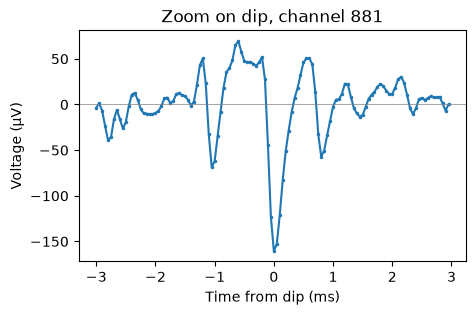

In [20]:
i_min = np.argmin(v_filt) # sample index of the deepest dip in the window
t_min = time[i_min] # its time in s
print(f"Deepest dip: {v_filt[i_min]:.1f} µV at t = {t_min:.4f} s") # where the candidate spike is

win = int(0.003 * fs) # 3 ms in samples (0.003 s × 20000 Hz = 60)
a, b = max(i_min - win, 0), min(i_min + win, len(v_filt)) # window edges, kept inside the data
plt.figure(figsize=(5, 3)) # small figure for one spike
plt.plot((time[a:b] - t_min) * 1000, v_filt[a:b], color="tab:blue", marker=".", ms=3) # x in ms relative to the dip; dots = individual samples
plt.axhline(0, color="grey", lw=0.5) # 0 µV reference line
plt.xlabel("Time from dip (ms)") # x label with units
plt.ylabel("Voltage (µV)") # y label with units
plt.title(f"Zoom on dip, channel {rec.get_channel_ids()[ch]}") # title follows your channel choice
plt.show() # draw it

Filtered data shape (samples, channels): (1201200, 25)
Noise σ per channel (µV): [5.5 5.6 5.3 6.6 4.6 5.6 5.2 6.8 5.3 6.1 5.2 6.9 5.6 4.7 5.4 5.6 5.9 5.9
 5.7 5.5 5.3 6.1 5.2 5.5 5.5]
Threshold per channel (µV): [-27.3 -27.8 -26.7 -32.9 -22.8 -28.2 -25.9 -34.2 -26.4 -30.3 -25.8 -34.4
 -28.1 -23.6 -27.1 -28.  -29.5 -29.5 -28.6 -27.3 -26.3 -30.5 -25.9 -27.3
 -27.4]

idx    ID  noise µV   thr µV  spikes  rate Hz
  0   877       5.5    -27.3      20     0.33
  1   881       5.6    -27.8     292     4.86
  2   889       5.3    -26.7     221     3.68
  3   896       6.6    -32.9     250     4.16
  4   897       4.6    -22.8     187     3.11
  5   900       5.6    -28.2     249     4.15
  6   901       5.2    -25.9      84     1.40
  7   904       6.8    -34.2     155     2.58
  8   909       5.3    -26.4      11     0.18
  9   913       6.1    -30.3      14     0.23
 10   917       5.2    -25.8      98     1.63
 11   920       6.9    -34.4      82     1.37
 12   925       5.6    -28.1     28

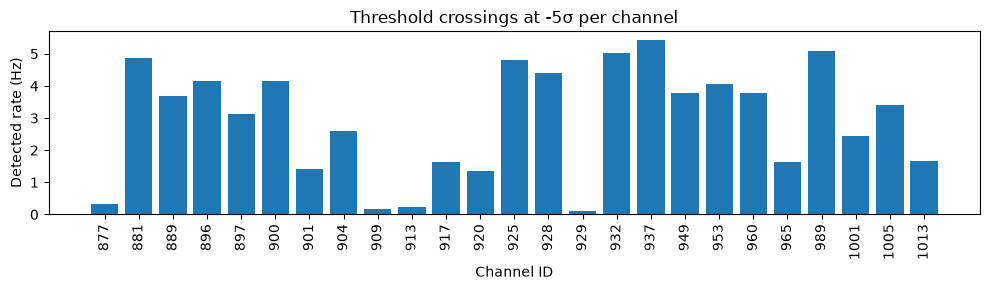

In [21]:
traces_f = rec_f.get_traces(return_in_uV=True) # load ALL filtered data (60 s × 25 ch, ~115 MiB: fine for this small file)
print("Filtered data shape (samples, channels):", traces_f.shape) # expect (1201200, 25)

noise = np.median(np.abs(traces_f), axis=0) / 0.6745 # noise σ per channel, in µV (axis=0 = down each column)
k = 5 # threshold multiplier; change freely
thr = -k * noise # one negative threshold per channel, in µV
print("Noise σ per channel (µV):", np.round(noise, 1)) # 25 values
print("Threshold per channel (µV):", np.round(thr, 1)) # 25 values, = -5 × noise

below = traces_f < thr # True wherever the voltage is under that channel's threshold
crossings = below[1:] & ~below[:-1] # True only at the first sample of each dip (was above, now below)
n_spk = crossings.sum(axis=0) # number of detected spikes per channel
rate = n_spk / dur # spikes per second (Hz) per channel; dur from the first cell
ids = rec.get_channel_ids() # channel IDs for labels

print(f"\n{'idx':>3} {'ID':>5} {'noise µV':>9} {'thr µV':>8} {'spikes':>7} {'rate Hz':>8}") # table header
for i in range(n_ch): # one row per channel
    print(f"{i:>3} {ids[i]:>5} {noise[i]:>9.1f} {thr[i]:>8.1f} {n_spk[i]:>7} {rate[i]:>8.2f}") # values for channel i
print(f"\nTotal detected: {n_spk.sum()} spikes on {n_ch} channels") # overall count

plt.figure(figsize=(10, 3)) # wide figure, one bar per channel
plt.bar(range(n_ch), rate, color="tab:blue") # firing rate per channel
plt.xticks(range(n_ch), ids, rotation=90) # label bars with channel IDs
plt.xlabel("Channel ID") # x label
plt.ylabel("Detected rate (Hz)") # y label with units
plt.title(f"Threshold crossings at -{k}σ per channel") # title follows k
plt.tight_layout() # avoid overlapping labels
plt.show() # draw it